# Digital Twin Challenge: an E. coli colony in a microfluidic chamber

**Team:** Alex Williams & Brandon Townsend

We build a digital twin of 248 real *E. coli* cells growing in a 34 × 60 µm chamber, starting from the
first microscope frame, and predict the colony for 135 minutes (the last 70 minutes are hidden from us).
The twin is built with **Vivarium** (`process-bigraph`) and **Viva-munk** (`multi-cell`: 2D cell physics).

**How we worked:** every rule is *measured* from the tracking data first, then added to the twin on its
own, and we report what it changed (cell count and area against the real cells, % error, several seeds).

**Run:** Runtime → Run all. The first cell installs the pinned packages and downloads the challenge data.

## Step 1: set up
Installs the exact versions required by the challenge (Viva-munk at the pinned commit), and fetches the
challenge repository (data + reference images) if it is not already next to this notebook.

In [1]:
import importlib.util, subprocess, sys, os
from pathlib import Path

PINS = ["multi-cell @ git+https://github.com/SamOliveiraLab/Viva-munk.git@3fc41887e17f9a435080a751e106e04223446185",
        "process-bigraph==1.1.4", "bigraph-schema==1.1.3", "pymunk==7.2.0"]
if importlib.util.find_spec("multi_cell") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PINS], check=True)

# Find the challenge data: next to the notebook, in our repo's refs/, or download it.
CANDIDATES = [Path("Digital-Twin-Challenge"), Path("../refs/digital-twin-challenge"),
              Path("refs/digital-twin-challenge")]
REF = next((p for p in CANDIDATES if (p / "data" / "frame0_cells.csv").exists()), None)
if REF is None:
    subprocess.run(["git", "clone", "-q", "https://github.com/SamOliveiraLab/Digital-Twin-Challenge"], check=True)
    REF = Path("Digital-Twin-Challenge")
DATA = REF / "data"
print("challenge data in", DATA.resolve())

challenge data in /Users/alexwilliams/Developer/hackathon/jsnn-hackathon/refs/digital-twin-challenge/data


In [2]:
import json, math, random, io, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from PIL import Image
from IPython.display import display, Image as NotebookImage, Markdown

from process_bigraph import Composite, gather_emitter_results
from process_bigraph.emitter import emitter_from_wires
from multi_cell import core_import
from multi_cell.processes.grow_divide import AdderGrowDivide, make_adder_grow_divide_process
from multi_cell.processes.remove_crossing import make_remove_crossing_process

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

CHAMBER = json.loads((DATA / "chamber.json").read_text())
W, H = float(CHAMBER["width_um"]), float(CHAMBER["height_um"])   # 34 x 60 um, open side at x = W
FRAME_S = float(CHAMBER["frame_interval_s"])                      # 300 s between frames
N_FRAMES = 28                                                     # frames 0..27 = 0..135 min
SEEDS = [0, 1, 2]

Matplotlib is building the font cache; this may take a moment.


## Step 2: look at the data
What the cells do: in 65 minutes the colony goes from 248 to 337 cells, and the area they cover from 570 to
700 µm². Cells are rods (capsules) about 1 µm wide and 2–5 µm long. Food arrives from the right (x = 34 µm).

248 cells in frame 0, 447 cells tracked over frames 0-13, 184 of them born by division


,cell_id,x_um,y_um,length_um,width_um,angle_rad,area_um2
count,248.00,248.00,248.00,248.00,248.00,248.00,248.00
mean,124.50,11.91,23.96,2.52,0.99,1.47,2.30
std,71.74,7.24,16.26,0.75,0.12,0.89,0.83
min,1.00,0.70,0.68,1.36,0.61,0.01,1.02
25%,62.75,6.43,10.58,2.01,0.91,0.64,1.76
50%,124.50,10.98,21.26,2.37,0.98,1.45,2.11
75%,186.25,16.20,36.96,2.87,1.06,2.19,2.65
max,248.00,32.92,58.61,6.39,1.58,3.12,6.43


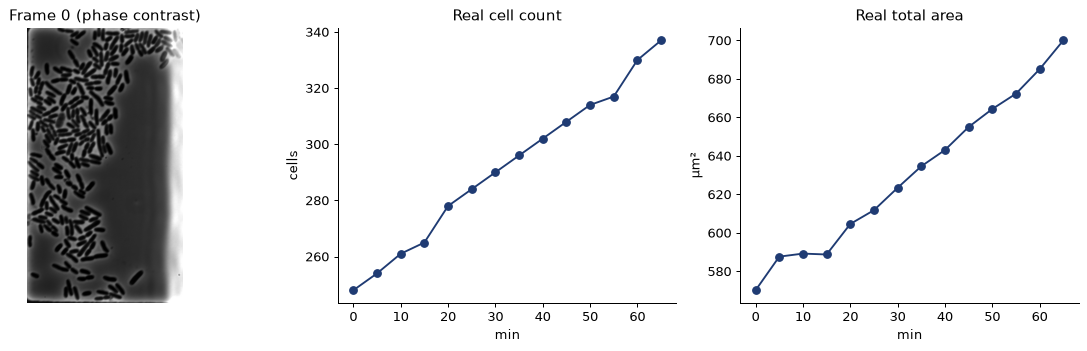

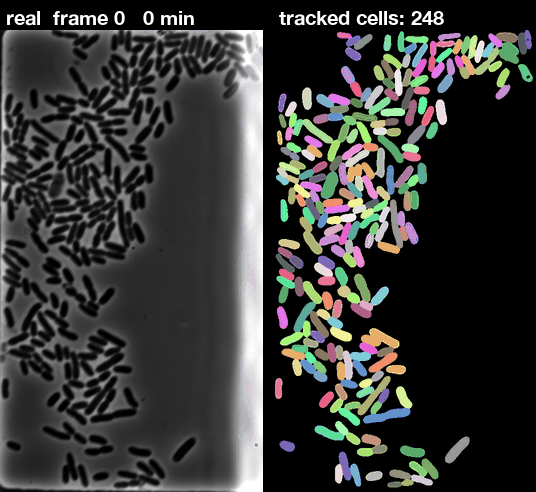

In [3]:
frame0 = pd.read_csv(DATA / "frame0_cells.csv")
tracks = pd.read_csv(DATA / "tracks_0-13.csv")
lineage = pd.read_csv(DATA / "lineage_0-13.csv")
real = pd.read_csv(DATA / "real_counts_0-13.csv")
print(f"{len(frame0)} cells in frame 0, {tracks.cell_id.nunique()} cells tracked over frames 0-13, "
      f"{(lineage.parent_id > 0).sum()} of them born by division")
display(frame0.describe().round(2))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(Image.open(DATA / "real_frame0_phase.png"), cmap="gray"); ax[0].set_title("Frame 0 (phase contrast)"); ax[0].axis("off")
ax[1].plot(real.time_min, real.cells, "o-", color="#1f3b73"); ax[1].set(title="Real cell count", xlabel="min", ylabel="cells")
ax[2].plot(real.time_min, real.total_area_um2, "o-", color="#1f3b73"); ax[2].set(title="Real total area", xlabel="min", ylabel="µm²")
plt.tight_layout(); plt.show()
display(NotebookImage(data=(DATA / "real_movie_0-13.gif").read_bytes(), format="gif"))

## Step 3: start the twin from the first picture

**Building blocks (Vivarium):** the *state* holds every cell; *processes* change it each tick (physics,
growth/division); a *step* removes cells that leave the chamber; the *emitter* records the state.

**Conversions we had to get right:**
* Viva-munk's `length` is only the straight middle part of the capsule: `length = length_um − width_um`,
  `radius = width_um / 2`. (Check below: our capsule areas reproduce the real 570 µm² at t = 0.)
* Viva-munk's chamber has walls on all four sides. To make the right side *open*, the physics box is 10 µm
  wider than the chamber and a `RemoveCrossing` step deletes every cell whose centre passes x = 34 µm.
* We count cells and area only inside the 34 × 60 µm camera window, like the microscope.

In [4]:
def capsule_area(mid_length, radius):
    return mid_length * 2 * radius + math.pi * radius ** 2


def frame0_agents():
    agents = {}
    for r in frame0.itertuples():
        radius = r.width_um / 2
        mid = max(r.length_um - r.width_um, 0.05)
        aid = f"c{r.cell_id}"
        agents[aid] = dict(id=aid, type="segment", mass=0.02 * capsule_area(mid, radius),
                           length=mid, radius=radius, angle=float(r.angle_rad),
                           location=(float(r.x_um), float(r.y_um)), velocity=(0.0, 0.0), elasticity=0.1)
    return agents


a0 = frame0_agents()
print(f"capsule area at t=0: {sum(capsule_area(a['length'], a['radius']) for a in a0.values()):.1f} µm² "
      f"(real: {real.total_area_um2[0]:.1f} µm²)")

capsule area at t=0: 569.0 µm² (real: 570.2 µm²)


**Our growth/division process.** We use Viva-munk's `AdderGrowDivide` (exponential growth, divide after adding
Δ µm) with three small extensions, each tied to something we measured:
1. **Frame-0 cells are not newborn.** `AdderGrowDivide` assumes a cell was born at its current length, so every
   cell in the first picture would wait a whole extra cycle before dividing. We give each frame-0 cell an
   estimated birth length instead (Step 5).
2. **Daughter length.** Real daughters are each half of the mother's *total* length; Viva-munk halves the
   middle part, which makes daughters `radius` too long. We correct that.
3. **Position (rule 3).** The growth rate can be scaled by the cell's distance from the opening.

In [5]:
BIRTH_MID = {}   # frame-0 cell id -> estimated birth length (middle part), filled in Step 5


class TwinGrowDivide(AdderGrowDivide):
    config_schema = {**AdderGrowDivide.config_schema,
                     "x_slope": {"_type": "float", "_default": 0.0},   # relative change in growth rate per µm of x
                     "x_ref": {"_type": "float", "_default": 0.0},
                     "use_birth_estimate": {"_type": "boolean", "_default": False},
                     "fix_daughter_length": {"_type": "boolean", "_default": False}}

    def _daughter_config(self):
        cfg = super()._daughter_config()
        for k in ("x_slope", "x_ref", "fix_daughter_length"):
            cfg[k] = self.config[k]
        cfg["use_birth_estimate"] = False          # daughters really are newborn
        return cfg

    def _ensure_initialized(self, agent, rng):
        fresh = not self._initialized
        super()._ensure_initialized(agent, rng)
        if fresh and self.config["use_birth_estimate"] and agent.get("id") in BIRTH_MID:
            self._birth_length = min(BIRTH_MID[agent["id"]], float(agent["length"]))

    def update(self, state, interval):
        agent = state["agents"].get(state["agent_id"], {})
        if agent:
            self._ensure_initialized(agent, random)
        base = self._alpha_per_s
        if agent and self.config["x_slope"]:
            x = float(agent["location"][0])
            self._alpha_per_s = base * max(0.05, 1 + self.config["x_slope"] * (x - self.config["x_ref"]))
        try:
            out = super().update(state, interval)
        finally:
            self._alpha_per_s = base
        if self.config["fix_daughter_length"]:
            for d in out["agents"].get("_add", {}).values():
                new = max(d["length"] - d["radius"], 0.05)
                d["mass"] *= capsule_area(new, d["radius"]) / capsule_area(d["length"], d["radius"])
                d["length"] = new
        return out


def build_document(rules):
    """rules: dict of AdderGrowDivide/TwinGrowDivide config values, or None for 'no growth'."""
    agents = frame0_agents()
    if rules is not None:
        for a in agents.values():
            a["grow_divide"] = make_adder_grow_divide_process(dict(rules, agents_key="cells"), agents_key="cells")
            a["grow_divide"]["address"] = "local:TwinGrowDivide"
    return {
        "cells": agents, "particles": {},
        "multibody": {"_type": "process", "address": "local:PymunkProcess",
                      "config": {"env_size": W + 10.0, "env_height": H, "elasticity": 0.1},
                      "interval": 30.0,
                      "inputs": {"segment_cells": ["cells"], "circle_particles": ["particles"]},
                      "outputs": {"segment_cells": ["cells"], "circle_particles": ["particles"]}},
        "remove_crossing": make_remove_crossing_process(x_max=W, agents_key="cells"),
        "emitter": emitter_from_wires({"agents": ["cells"], "time": ["global_time"]}),
    }


def run_twin(rules, seed=0, frames=N_FRAMES, keep_cells=False):
    """Run the twin; return a per-frame table (count, area inside the window) and optionally the cells."""
    random.seed(seed); np.random.seed(seed)
    core = core_import()
    core.register_link("TwinGrowDivide", TwinGrowDivide)
    sim = Composite({"state": build_document(rules)}, core=core)
    sim.run((frames - 1) * FRAME_S)
    results = gather_emitter_results(sim)[("emitter",)]
    by_time = {round(s["time"]): s["agents"] for s in results}
    rows, snaps = [], []
    for f in range(frames):
        cells = by_time.get(round(f * FRAME_S), {})
        inside = [c for c in cells.values()
                  if 0 <= c["location"][0] <= W and 0 <= c["location"][1] <= H]
        rows.append(dict(frame=f, time_min=f * FRAME_S / 60, cells=len(inside),
                         total_area_um2=sum(capsule_area(c["length"], c["radius"]) for c in inside)))
        if keep_cells:
            snaps.append([(c["location"], c["angle"], c["length"], c["radius"]) for c in inside])
    out = pd.DataFrame(rows)
    return (out, snaps) if keep_cells else out


def run_seeds(rules, seeds=SEEDS):
    runs = [run_twin(rules, s) for s in seeds]
    mean = sum(r[["cells", "total_area_um2"]] for r in runs) / len(runs)
    return pd.concat([runs[0][["frame", "time_min"]], mean], axis=1), runs


def pct_error(sim, col):
    """Average gap between twin and real over frames 0-13, as % of the real value (lower is better)."""
    s = sim.set_index("frame")[col].reindex(real.frame)
    return float((abs(s.values - real[col].values) / real[col].values).mean() * 100)


def show_vs_real(name, sim, runs):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for col, a, lab in [("cells", ax[0], "cells"), ("total_area_um2", ax[1], "total area (µm²)")]:
        for r in runs:
            a.plot(r.time_min[:14], r[col][:14], color="#e07b39", alpha=0.25, lw=1)
        a.plot(sim.time_min[:14], sim[col][:14], color="#e07b39", lw=2.5, label=f"twin: {name} (mean of {len(runs)} seeds)")
        a.plot(real.time_min, real[col], "o", color="#1f3b73", label="real cells")
        a.set(xlabel="time (min)", ylabel=lab)
    ax[0].legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()
    err = dict(rules=name, count_error_pct=round(pct_error(sim, "cells"), 2),
               area_error_pct=round(pct_error(sim, "total_area_um2"), 2))
    display(pd.DataFrame([err]))
    return err


RESULTS, ERRORS = {}, []

**Baseline (no rules yet): physics only.** The cells should sit exactly where the real ones are.

one short run took 0.4 s


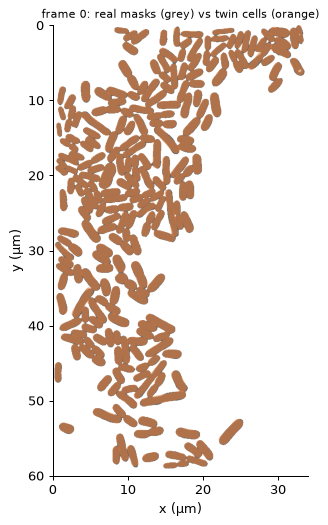

In [6]:
t0 = time.time()
base, base_snaps = run_twin(None, seed=0, frames=2, keep_cells=True)
print(f"one short run took {time.time() - t0:.1f} s")


def draw_cells(ax, cells, color="#e07b39", alpha=0.85):
    for (x, y), ang, mid, r in cells:
        dx, dy = math.cos(ang), math.sin(ang)
        h = mid / 2
        t = np.linspace(-np.pi / 2, np.pi / 2, 8)
        end1 = [(x + dx * h + r * (math.cos(s) * dx - math.sin(s) * dy), y + dy * h + r * (math.cos(s) * dy + math.sin(s) * dx)) for s in t]
        end2 = [(x - dx * h - r * (math.cos(s) * dx - math.sin(s) * dy), y - dy * h - r * (math.cos(s) * dy + math.sin(s) * dx)) for s in t]
        ax.add_patch(Polygon(end1 + end2, closed=True, fc=color, ec="none", alpha=alpha))
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_aspect("equal")


masks = np.load(DATA / "real_masks_0-13.npz")
LABELS, PX = masks["labels"], float(masks["pixel_um"])
fig, ax = plt.subplots(figsize=(4, 6.5))
ax.imshow(LABELS[0] > 0, cmap="Greys", extent=(0, LABELS.shape[2] * PX, LABELS.shape[1] * PX, 0), alpha=0.6)
draw_cells(ax, base_snaps[0], alpha=0.6)
ax.set_title("frame 0: real masks (grey) vs twin cells (orange)", fontsize=9); ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
plt.show()

## Step 4: rule 1, cells grow

**Measurement.** For every tracked cell with at least 4 frames we fit both a straight line to `length` and a
straight line to `log(length)` against time. Exponential growth (same *percentage* per minute) means the
absolute growth speed should increase with cell length, and `log(length)` should be a straight line.

369 cells fitted
growth rate α: median 0.00481 /min = 0.289 /h  ->  doubling time 144 min
cell-to-cell spread (robust CV): 0.31
longer cells grow faster in µm/min (r = 0.55): consistent with exponential growth


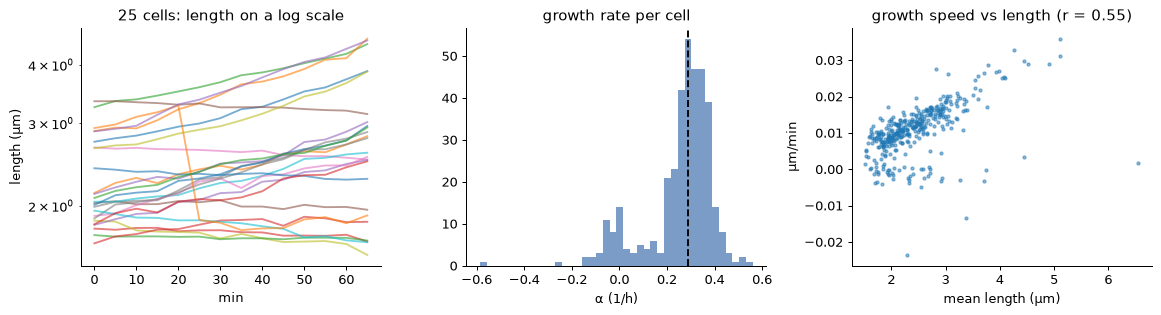

In [7]:
fits = []
for cid, g in tracks.groupby("cell_id"):
    if len(g) < 4:
        continue
    t, L = g.time_min.values, g.length_um.values
    alpha, _ = np.polyfit(t, np.log(L), 1)          # 1/min
    lin_speed, _ = np.polyfit(t, L, 1)             # µm/min
    fits.append(dict(cell_id=cid, alpha_per_min=alpha, speed_um_per_min=lin_speed,
                     mean_length=L.mean(), x_um=g.x_um.mean(), frames=len(g)))
fits = pd.DataFrame(fits)
med = fits.alpha_per_min.median()
q1, q3 = fits.alpha_per_min.quantile([0.25, 0.75])
ALPHA_PER_H = med * 60
ALPHA_CV = (q3 - q1) / 1.349 / med                    # robust spread (segmentation noise inflates the plain std)
r_speed = np.corrcoef(fits.mean_length, fits.speed_um_per_min)[0, 1]
print(f"{len(fits)} cells fitted")
print(f"growth rate α: median {med:.5f} /min = {ALPHA_PER_H:.3f} /h  ->  doubling time {np.log(2) / med:.0f} min")
print(f"cell-to-cell spread (robust CV): {ALPHA_CV:.2f}")
print(f"longer cells grow faster in µm/min (r = {r_speed:.2f}): consistent with exponential growth")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for cid in fits.sort_values("frames", ascending=False).cell_id[:25]:
    g = tracks[tracks.cell_id == cid]
    ax[0].plot(g.time_min, g.length_um, alpha=0.6)
ax[0].set(yscale="log", title="25 cells: length on a log scale", xlabel="min", ylabel="length (µm)")
ax[1].hist(fits.alpha_per_min * 60, bins=40, color="#7a9cc6"); ax[1].axvline(ALPHA_PER_H, color="k", ls="--")
ax[1].set(title="growth rate per cell", xlabel="α (1/h)")
ax[2].scatter(fits.mean_length, fits.speed_um_per_min, s=6, alpha=0.5)
ax[2].set(title=f"growth speed vs length (r = {r_speed:.2f})", xlabel="mean length (µm)", ylabel="µm/min")
plt.tight_layout(); plt.show()

**Twin with rule 1.** Cells grow exponentially at the measured rate (each cell draws its own α from the
measured median and spread). There is no division yet, so the count can only stay flat or drop as cells
are pushed out of the opening.

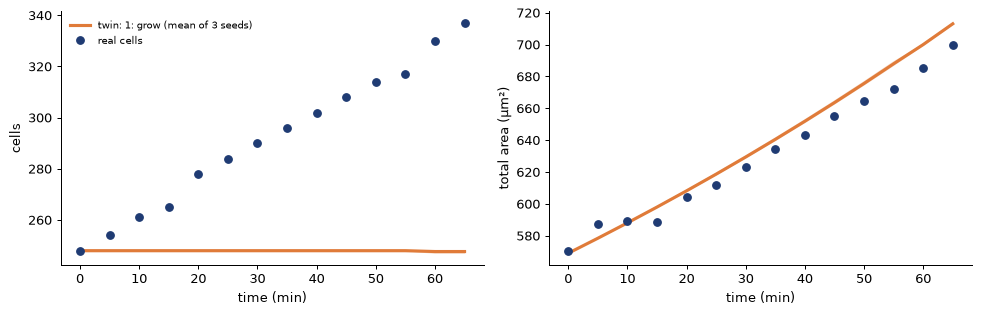

,rules,count_error_pct,area_error_pct
0,1: grow,14.25,1.28


In [8]:
RULE1 = dict(alpha_mean_per_h=ALPHA_PER_H, alpha_cv=ALPHA_CV, delta_mean=1e6, delta_cv=0.0, pressure_k=0.0)
sim, runs = run_seeds(RULE1)
RESULTS["1: grow"] = (sim, runs)
ERRORS.append(show_vs_real("1: grow", sim, runs))

## Step 5: rule 2, cells divide

**Measurement.** `lineage_0-13.csv` tells us every mother and her two daughters. We compare the mother's
length in her last frame (length at division) with her daughters' lengths in their first frame (length at
birth). The adder rule says a cell divides after *adding* a fixed length Δ since its birth.

**Honest caveat:** the doubling time (~2.4 h) is longer than the 65 minutes we can see, so almost no cell is
seen from birth to division. We therefore estimate Δ as (mean length at division − mean length at birth),
which is what the adder predicts in a steady colony, and check that daughters are half their mother.

92 divisions seen; 2 complete cycles (birth and division both seen)
length at division 3.61 µm (CV 0.20), daughter length at birth 1.93 µm
daughters together = 1.07 x mother  -> each daughter is about half
added length Δ ≈ 1.68 µm


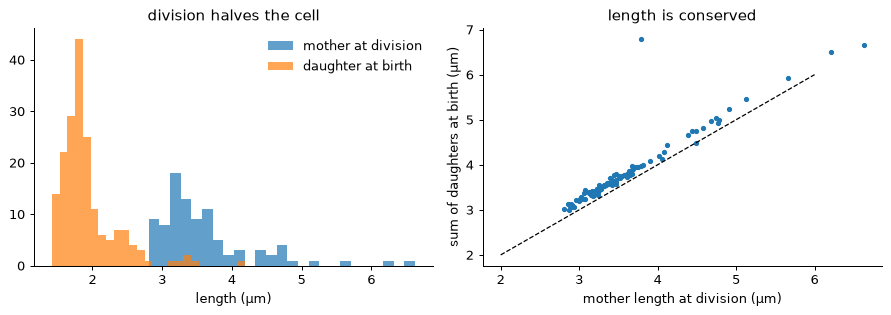

In [9]:
first = tracks.sort_values("frame").groupby("cell_id").first()
last = tracks.sort_values("frame").groupby("cell_id").last()
kids = lineage[lineage.parent_id > 0].copy()
kids["L_birth"] = first.loc[kids.cell_id, "length_um"].values
mothers = kids.groupby("parent_id").agg(n=("cell_id", "size"), kids_total=("L_birth", "sum"))
mothers["L_div"] = last.loc[mothers.index, "length_um"].values
mothers = mothers[mothers.n == 2]
L_DIV, L_BIRTH = mothers.L_div.mean(), kids.L_birth.mean()
DELTA = L_DIV - L_BIRTH
DELTA_CV = mothers.L_div.std() / L_DIV
full = lineage[(lineage.parent_id > 0) & lineage.cell_id.isin(mothers.index)]
print(f"{len(mothers)} divisions seen; {len(full)} complete cycles (birth and division both seen)")
print(f"length at division {L_DIV:.2f} µm (CV {DELTA_CV:.2f}), daughter length at birth {L_BIRTH:.2f} µm")
print(f"daughters together = {(mothers.kids_total / mothers.L_div).mean():.2f} x mother  -> each daughter is about half")
print(f"added length Δ ≈ {DELTA:.2f} µm")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(mothers.L_div, bins=25, alpha=0.7, label="mother at division")
ax[0].hist(kids.L_birth, bins=25, alpha=0.7, label="daughter at birth")
ax[0].set(xlabel="length (µm)", title="division halves the cell"); ax[0].legend(frameon=False)
ax[1].scatter(mothers.L_div, mothers.kids_total, s=10); ax[1].plot([2, 6], [2, 6], "k--", lw=1)
ax[1].set(xlabel="mother length at division (µm)", ylabel="sum of daughters at birth (µm)", title="length is conserved")
plt.tight_layout(); plt.show()

**Where are frame-0 cells in their cycle?** A long cell in the first picture is probably about to divide.
Under the adder rule a cell is born at about `L_birth` and divides at `L_birth + Δ`, so for each frame-0 cell we
set its birth length to `min(current length, L_birth)`: short cells are treated as newborn, long cells have
already added most of their Δ and divide soon.

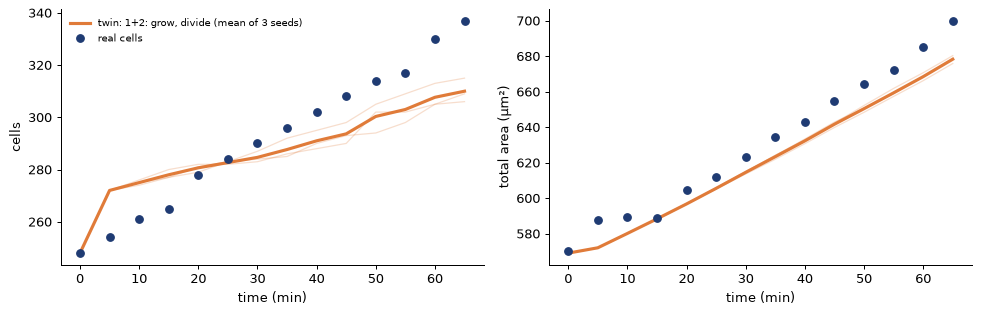

,rules,count_error_pct,area_error_pct
0,"1+2: grow, divide",3.95,1.66


In [10]:
for r in frame0.itertuples():
    BIRTH_MID[f"c{r.cell_id}"] = max(min(r.length_um, L_BIRTH) - r.width_um, 0.05)

RULE2 = dict(RULE1, delta_mean=DELTA, delta_cv=DELTA_CV, division_noise_cv=0.07,
             use_birth_estimate=True, fix_daughter_length=True)
sim, runs = run_seeds(RULE2)
RESULTS["1+2: grow, divide"] = (sim, runs)
ERRORS.append(show_vs_real("1+2: grow, divide", sim, runs))

## Step 6: rule 3, position

**Measurement.** Fresh medium arrives through the open side (x = 34 µm). Do cells near it grow faster? We
compare each cell's growth rate (Step 4) with its average x position.

α vs x: +0.60% per µm (r = 0.08); a cell at the opening grows +13% vs the average cell


,median α (1/h),count
x_bin,,
"(0, 6]",0.270,82
"(6, 12]",0.293,114
"(12, 18]",0.296,109
"(18, 24]",0.289,33
"(24, 30]",0.332,22
"(30, 34]",0.321,9


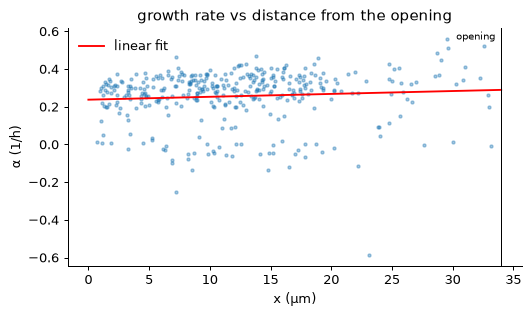

In [11]:
fits["x_bin"] = pd.cut(fits.x_um, [0, 6, 12, 18, 24, 30, 34])
by_x = fits.groupby("x_bin", observed=True).alpha_per_min.agg(["median", "count"])
slope, intercept = np.polyfit(fits.x_um, fits.alpha_per_min, 1)
X_REF = float(fits.x_um.mean())
X_SLOPE = slope / (slope * X_REF + intercept)             # relative change of α per µm
r_x = np.corrcoef(fits.x_um, fits.alpha_per_min)[0, 1]
print(f"α vs x: {X_SLOPE * 100:+.2f}% per µm (r = {r_x:.2f}); "
      f"a cell at the opening grows {X_SLOPE * (W - X_REF) * 100:+.0f}% vs the average cell")
display((by_x.assign(median=lambda d: d["median"] * 60).rename(columns={"median": "median α (1/h)"})).round(3))

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(fits.x_um, fits.alpha_per_min * 60, s=6, alpha=0.4)
xs = np.linspace(0, W, 50); ax.plot(xs, (slope * xs + intercept) * 60, "r-", label="linear fit")
ax.axvline(W, color="k", lw=0.8); ax.text(W - 0.5, ax.get_ylim()[1] * 0.9, "opening", ha="right", fontsize=8)
ax.set(xlabel="x (µm)", ylabel="α (1/h)", title="growth rate vs distance from the opening"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

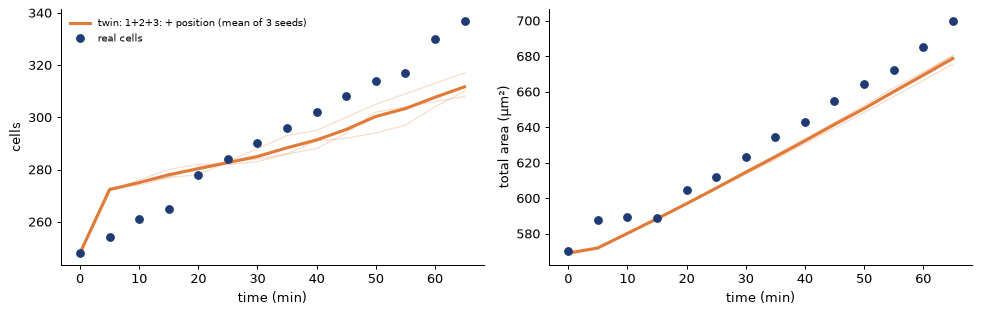

,rules,count_error_pct,area_error_pct
0,1+2+3: + position,3.84,1.64


In [12]:
RULE3 = dict(RULE2, x_slope=X_SLOPE, x_ref=X_REF)
sim, runs = run_seeds(RULE3)
RESULTS["1+2+3: + position"] = (sim, runs)
ERRORS.append(show_vs_real("1+2+3: + position", sim, runs))

## Step 7: final result
(a) cell count and (b) total area, each divided by its value at minute 0, one line per set of rules
(mean of the seeds), against the real cells. The grey part (70–135 min) is the hidden period we predict.

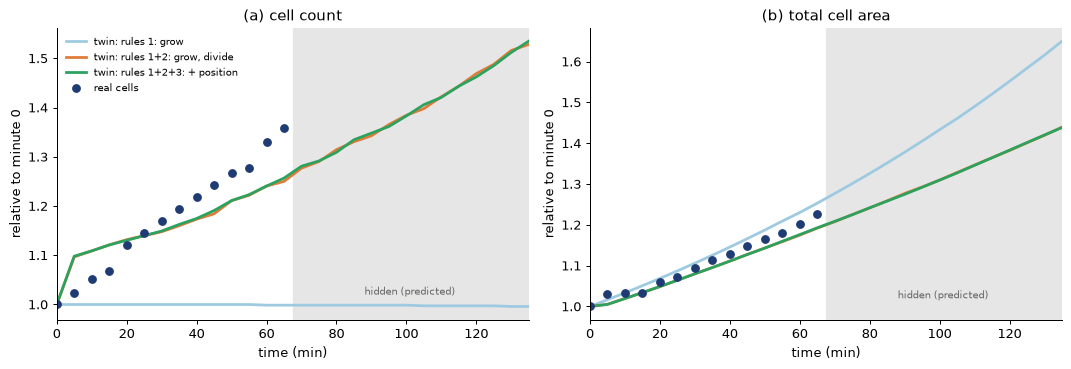

**% error against the real cells, frames 0–13 (lower is better)**

,rules,cell count % error,cell area % error
0,1: grow,14.25,1.28
1,"1+2: grow, divide",3.95,1.66
2,1+2+3: + position,3.84,1.64


prediction for frames 0-27 from rules 1+2+3: + position saved to my_prediction.csv


In [13]:
COLORS = {"1: grow": "#9ecae1", "1+2: grow, divide": "#e07b39", "1+2+3: + position": "#2ca25f"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, col, title in [(ax[0], "cells", "(a) cell count"), (ax[1], "total_area_um2", "(b) total cell area")]:
    a.axvspan(67.5, 135, color="0.9", zorder=0); a.text(101, 1.02, "hidden (predicted)", ha="center", fontsize=8, color="0.4")
    for name, (sim, _) in RESULTS.items():
        a.plot(sim.time_min, sim[col] / sim[col][0], lw=2.2, color=COLORS[name], label=f"twin: rules {name}")
    a.plot(real.time_min, real[col] / real[col][0], "o", color="#1f3b73", label="real cells")
    a.set(title=title, xlabel="time (min)", ylabel="relative to minute 0", xlim=(0, 135))
ax[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

table = pd.DataFrame(ERRORS).rename(columns={"rules": "rules", "count_error_pct": "cell count % error",
                                             "area_error_pct": "cell area % error"})
display(Markdown("**% error against the real cells, frames 0–13 (lower is better)**"))
display(table)

best = list(RESULTS)[-1]
pred = RESULTS[best][0].round(3)
pred.to_csv("my_prediction.csv", index=False)
print(f"prediction for frames 0-27 from rules {best} saved to my_prediction.csv")

**Video: our twin next to the real cells.** Left: the real cells (frames 0–13; after 65 min the real data is
hidden). Right: the twin with all rules, 0–135 min.

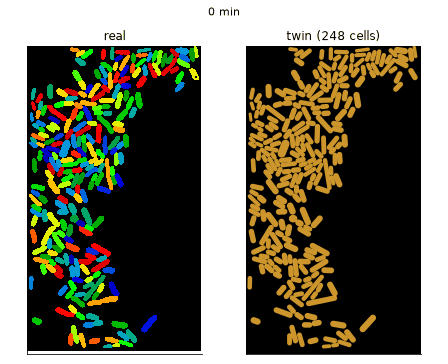

In [14]:
_, snaps = run_twin(RULE3, seed=SEEDS[0], keep_cells=True)
frames = []
ext = (0, LABELS.shape[2] * PX, LABELS.shape[1] * PX, 0)
for f in range(N_FRAMES):
    fig, ax = plt.subplots(1, 2, figsize=(6.4, 5.2))
    if f < len(LABELS):
        ax[0].imshow(np.where(LABELS[f] > 0, (LABELS[f] * 37) % 200 + 40, 0), cmap="nipy_spectral", extent=ext,
                     vmin=0, vmax=255, interpolation="nearest")
    else:
        ax[0].imshow(np.zeros((2, 2)), cmap="Greys", extent=ext)
        ax[0].text(W / 2, H / 2, "hidden", ha="center", color="0.5")
    ax[0].set(xlim=(0, W), ylim=(H, 0), title="real"); ax[0].set_aspect("equal")
    ax[1].set_facecolor("black"); draw_cells(ax[1], snaps[f], color="#f2b134")
    ax[1].set_title(f"twin ({len(snaps[f])} cells)")
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{f * 5} min", fontsize=11)
    plt.tight_layout()
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=70); plt.close(fig)
    buf.seek(0); frames.append(Image.open(buf).convert("RGB"))
gif = io.BytesIO()
frames[0].save(gif, format="GIF", save_all=True, append_images=frames[1:], duration=350, loop=0)
display(NotebookImage(data=gif.getvalue(), format="gif"))

## Step 8: discussion

DISCUSSION_PLACEHOLDER